## 🔍 EDA — исследовательский анализ данных

- [**1. 📁 Общая информация о датасете**](#section-1)
- [**2. 🖼️ Визуализация и анализ существующей разметки**](#section-2)
- [**3. 📊 Анализ распределения классов (брендов)**](#section-3)
- [**4. 📐 Анализ геометрических характеристик логотипов**](#section-4)
- [**5. ✅ Проверка качества и корректности разметки**](#section-5)
- [**6. 🔎 Анализ сложных случаев обнаружения логотипов**](#section-6)
- [**7. ⚖️ Сравнение обучающей, валидационной и тестовой выборок**](#section-7)
- [**8. 🧪 Исследование методов аугментации данных**](#section-8)
- [**9. 📝 Выводы и подготовка данных к обучению модели**](#section-9)

In [132]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
from PIL import Image
import random
import shutil

In [114]:
# Корневая папка проекта BrandSight
PROJECT_DIR = Path.cwd().parent

# Папка с датасетом
DATA_DIR = PROJECT_DIR / "data"

# Папки выборок
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

# Изображения
TRAIN_IMAGES = TRAIN_DIR / "images"
VAL_IMAGES = VAL_DIR / "images"
TEST_IMAGES = TEST_DIR / "images"

# Разметка
TRAIN_LABELS = TRAIN_DIR / "labels"
VAL_LABELS = VAL_DIR / "labels"
TEST_LABELS = DATA_DIR / "test" / "labels"

In [115]:
print("Корень проекта:", PROJECT_DIR)
print("Папка с данными:", DATA_DIR)
print("Папка существует:", DATA_DIR.exists())

Корень проекта: c:\Users\Huawei\Desktop\BrandSight
Папка с данными: c:\Users\Huawei\Desktop\BrandSight\data
Папка существует: True


<a id="section-1"></a>
### 1. 📁 Общая информация о датасете

In [104]:
train_images = list(TRAIN_IMAGES.iterdir())
val_images = list(VAL_IMAGES.iterdir())
test_images = list(TEST_IMAGES.iterdir())

print("Train:", len(train_images))
print("Validation:", len(val_images))
print("Test:", len(test_images))

Train: 867
Validation: 36
Test: 53


In [105]:
total_images = len(train_images) + len(val_images) + len(test_images)

In [106]:
print(f"Количество всех изображений: {total_images}")

Количество всех изображений: 956


In [ ]:
print(f"Доля тренировочных изображений: {round(100 * len(train_images) / total_images, 2)}%")
print(f"Доля валидационных изображений: {round(100 * len(val_images) / total_images, 2)}%")
print(f"Доля тестовых изображений: {round(100 * len(test_images) / total_images, 2)}%")

Доля тренировочных изображений: 90.69%
Доля валидационных изображений: 3.77%
Доля тестовых изображений: 5.54%


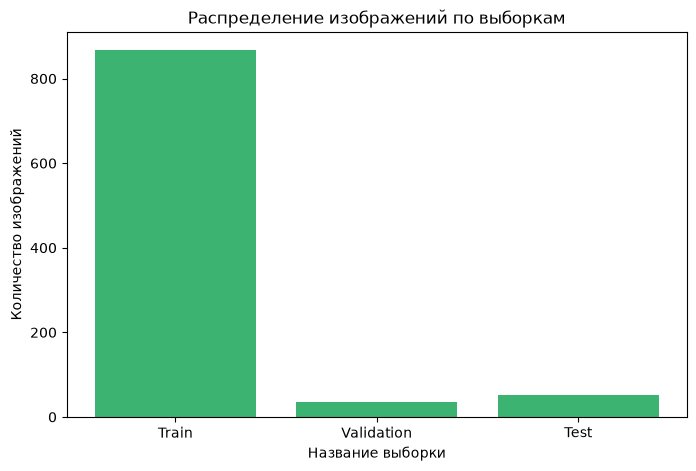

In [108]:
plt.figure(figsize=(8, 5))
plt.bar(["Train", "Validation", "Test"],
        [len(train_images), len(val_images), len(test_images)],
        color="mediumseagreen")

plt.title("Распределение изображений по выборкам")
plt.ylabel("Количество изображений")
plt.xlabel("Название выборки")
plt.show()

In [109]:
print("Разметка по Train:", len(list(TRAIN_LABELS.glob("*.txt"))))
print("Разметка по Validation:", len(list(VAL_LABELS.glob("*.txt"))))
print("Разметка по Test:", len(list(TEST_LABELS.glob("*.txt"))))

Разметка по Train: 943
Разметка по Validation: 55
Разметка по Test: 24


In [ ]:
for name, images, labels in [
    ("Train", TRAIN_IMAGES, TRAIN_LABELS),
    ("Validation", VAL_IMAGES, VAL_LABELS),
    ("Test", TEST_IMAGES, TEST_LABELS)
]:
    image_names = {f.stem for f in images.iterdir() if f.is_file()}
    label_names = {f.stem for f in labels.glob("*.txt")}

    print(f"\n{name}")
    print("Разметка без изображения:", len(label_names - image_names))
    print("Изображения без разметки:", len(image_names - label_names))


Train
Разметка без изображения: 119
Изображения без разметки: 43

Validation
Разметка без изображения: 19
Изображения без разметки: 0

Test
Разметка без изображения: 1
Изображения без разметки: 30


In [111]:
data = []

for name, images, labels in [
    ("Train", TRAIN_IMAGES, TRAIN_LABELS),
    ("Validation", VAL_IMAGES, VAL_LABELS),
    ("Test", TEST_IMAGES, TEST_LABELS)
]:
    image_names = {f.stem for f in images.iterdir() if f.is_file()}
    label_names = {f.stem for f in labels.glob("*.txt")}

    data.append({
        "Выборка": name,
        "Изображения": len(image_names),
        "Файлы разметки": len(label_names),
        "Разметка без изображения": len(label_names - image_names),
        "Изображения без разметки": len(image_names - label_names),
        "Совпадающие пары": len(image_names & label_names)
    })

eda_matching_df = pd.DataFrame(data)

display(eda_matching_df)

,Выборка,Изображения,Файлы разметки,Разметка без изображения,Изображения без разметки,Совпадающие пары
0,Train,867,943,119,43,824
1,Validation,36,55,19,0,36
2,Test,53,24,1,30,23


На этом этапе выявилась одна из первых серьёзных проблем проекта: версия датасета, опубликованная на Hugging Face, не соответствует данным, описанным в статье Exposure Engine.

Вероятно, на платформу загрузили не весь датасет или часть данных не была опубликована по соображениям безопасности. Я уже связался с авторами статьи и ожидаю ответа по поводу возможности получить полную версию датасета.

Пока продолжаю EDA, поскольку выявленные несоответствия не препятствуют дальнейшему анализу. Количество файлов без соответствующих изображений и изображений без разметки не превышает 10–15% от общего объёма данных, поэтому на данном этапе это не критично. Оставлю только совпадающие пары для 

Далее планирую изучить распределение логотипов по классам и проверить качество разметки непосредственно на изображениях. Это позволит оценить состояние датасета и выявить проблемы, которые могут повлиять на качество будущей модели.

### Очистка датасета 

In [121]:
CLEAN_DIR = DATA_DIR / "data_clean"

In [122]:
for split in ["train", "val", "test"]:
    images = DATA_DIR / split / "images"
    labels = DATA_DIR / split / "labels"

    for image in images.glob("*.jpg"):
        label = labels / (image.stem + ".txt")

        if label.exists():
            (CLEAN_DIR / split / "images").mkdir(parents=True, exist_ok=True)
            (CLEAN_DIR / split / "labels").mkdir(parents=True, exist_ok=True)

            shutil.copy(image, CLEAN_DIR / split / "images" / image.name)
            shutil.copy(label, CLEAN_DIR / split / "labels" / label.name)

In [123]:
# Папки выборок
TRAIN_DIR = DATA_DIR / "data_clean" / "train"
VAL_DIR = DATA_DIR / "data_clean" / "val"
TEST_DIR = DATA_DIR / "data_clean" / "test"

# Изображения
TRAIN_IMAGES = TRAIN_DIR / "images"
VAL_IMAGES = VAL_DIR / "images"
TEST_IMAGES = TEST_DIR / "images"

# Разметка
TRAIN_LABELS = TRAIN_DIR / "labels"
VAL_LABELS = VAL_DIR / "labels"
TEST_LABELS = TEST_DIR / "labels"

In [134]:
print("Размер файлов очищенного датасета:")
for name, folder in [("Train", TRAIN_DIR),
    ("Validation", VAL_DIR),
    ("Test", TEST_DIR)]:
    size = 0

    for root, dirs, files in os.walk(folder):
        for file in files:
            path = os.path.join(root, file)
            size += os.path.getsize(path)

    print(name, round(size / (1024 ** 2), 2), "MB")

Размер файлов очищенного датасета:
Train 115.32 MB
Validation 4.75 MB
Test 3.02 MB


In [136]:
formats = {}
sizes = {}

for folder in [TRAIN_IMAGES, VAL_IMAGES, TEST_IMAGES]:
    for file in folder.iterdir():
        img = Image.open(file)

        formats[img.format] = formats.get(img.format, 0) + 1
        sizes[img.size] = sizes.get(img.size, 0) + 1

print("Форматы изображений:", formats)
print("Разрешения изображений:", sizes)

Форматы изображений: {'JPEG': 883}
Разрешения изображений: {(1280, 720): 883}


Итоговая проверка очистки и текущее распределение изображений по выборкам:

In [137]:
for name, images, labels in [
    ("Train", TRAIN_IMAGES, TRAIN_LABELS),
    ("Validation", VAL_IMAGES, VAL_LABELS),
    ("Test", TEST_IMAGES, TEST_LABELS)
]:
    image_names = {f.stem for f in images.iterdir() if f.is_file()}
    label_names = {f.stem for f in labels.glob("*.txt")}

    print(f"\n{name}")
    print("Разметка без изображения:", len(label_names - image_names))
    print("Изображения без разметки:", len(image_names - label_names))


Train
Разметка без изображения: 0
Изображения без разметки: 0

Validation
Разметка без изображения: 0
Изображения без разметки: 0

Test
Разметка без изображения: 0
Изображения без разметки: 0


In [142]:
train_images = list(TRAIN_IMAGES.iterdir())
val_images = list(VAL_IMAGES.iterdir())
test_images = list(TEST_IMAGES.iterdir())
total_images = len(train_images) + len(val_images) + len(test_images)

print("Train:", len(train_images))
print("Validation:", len(val_images))
print("Test:", len(test_images))

Train: 824
Validation: 36
Test: 23


In [143]:
print(f"Количество всех изображений: {total_images}")
print(f"Доля тренировочных изображений: {round(100 * len(train_images) / total_images, 2)}%")
print(f"Доля валидационных изображений: {round(100 * len(val_images) / total_images, 2)}%")
print(f"Доля тестовых изображений: {round(100 * len(test_images) / total_images, 2)}%")

Количество всех изображений: 883
Доля тренировочных изображений: 93.32%
Доля валидационных изображений: 4.08%
Доля тестовых изображений: 2.6%


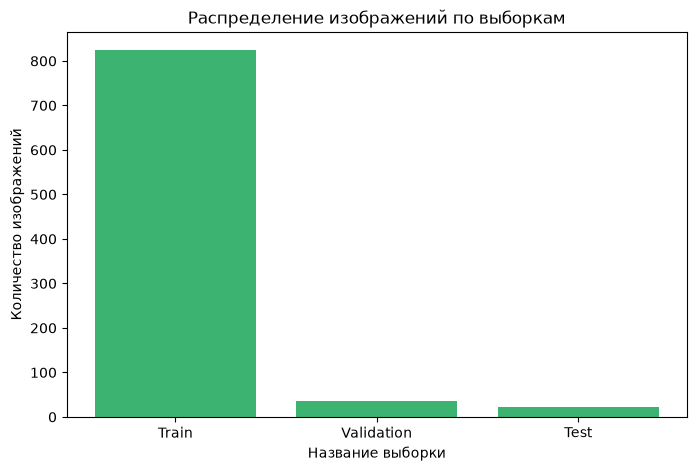

In [144]:
plt.figure(figsize=(8, 5))
plt.bar(["Train", "Validation", "Test"],
        [len(train_images), len(val_images), len(test_images)],
        color="mediumseagreen")

plt.title("Распределение изображений по выборкам")
plt.ylabel("Количество изображений")
plt.xlabel("Название выборки")
plt.show()

Текущего объёма данных достаточно для проведения первого эксперимента с обучением модели, а тестовую выборку планируется дополнить новыми изображениями из других матчей для более объективной оценки качества.

<a id="section-2"></a>
### 2. 🖼️ Визуализация и анализ существующей разметки

Для начала посмотрю в целом на картинки, которые находятся в каждой выборке:

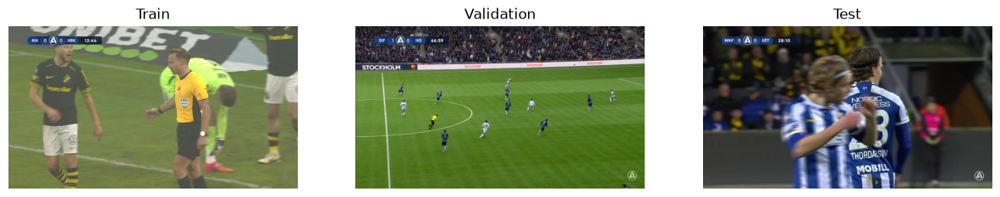

In [145]:
folders = [("Train", TRAIN_IMAGES),
    ("Validation", VAL_IMAGES),
    ("Test", TEST_IMAGES)]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (name, folder) in zip(axes, folders):
    images = list(folder.glob("*.jpg"))
    file = random.choice(images)

    ax.imshow(Image.open(file))
    ax.set_title(name)
    ax.axis("off")

plt.show()

Придумал следующие две функции, которые будут полезны мне во всем годовом проекте:
- show_all_logos() — отображает изображение со всеми логотипами, выделенными в соответствии с существующей разметкой.
- show_logo() — отображает изображение с выделением только логотипов выбранного класса (class_id).

In [176]:
def show_all_logos(image_file, label_file):
    image = Image.open(image_file)
    plt.imshow(image)
    data = np.loadtxt(label_file, ndmin=2)
    print("Class ID на изображении ниже:", np.unique(data[:, 0]).astype(int))

    for row in data:
        points = row[1:].reshape(4, 2) * [image.width, image.height]
        points = np.vstack([points, points[0]])
        plt.plot(points[:, 0], points[:, 1])

    plt.axis("off")
    plt.show()

In [177]:
def show_logo(image_file, label_file, class_id):
    image = Image.open(image_file)
    plt.imshow(image)
    data = np.loadtxt(label_file, ndmin=2)
    print(f"Class ID на изображении ниже:{class_id}")

    for row in data:
        if row[0] == class_id:
            points = row[1:].reshape(4, 2) * [image.width, image.height]
            points = np.vstack([points, points[0]])
            plt.plot(points[:, 0], points[:, 1])

    plt.axis("off")
    plt.show()

Опробую на случайном файле))

Class ID на изображении ниже: [261 264 395 476 525 600]


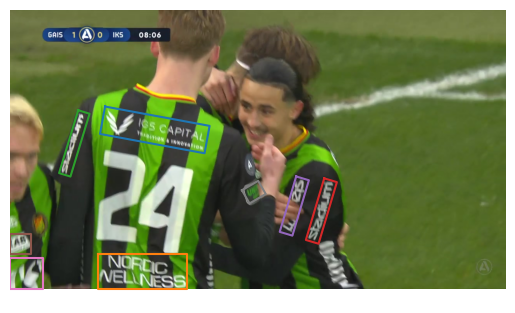

In [178]:
random.seed(42) # для воспроизводимости
random_image_file = random.choice(list(TRAIN_IMAGES.glob("*.jpg")))
random_label_file = TRAIN_LABELS / (random_image_file.stem + ".txt")

show_all_logos(random_image_file, random_label_file)

И опробую вторую функцию))

Class ID на изображении ниже:261


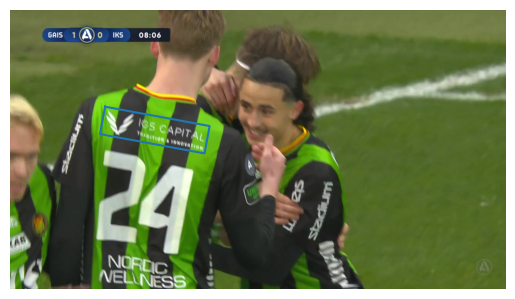

In [179]:
show_logo(random_image_file, random_label_file, 261)

Class ID на изображении ниже:395


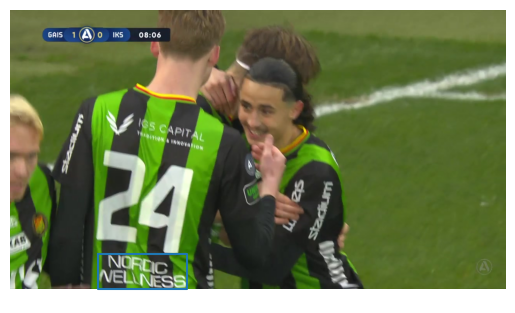

In [180]:
show_logo(random_image_file, random_label_file, 395)

Class ID на изображении ниже:525


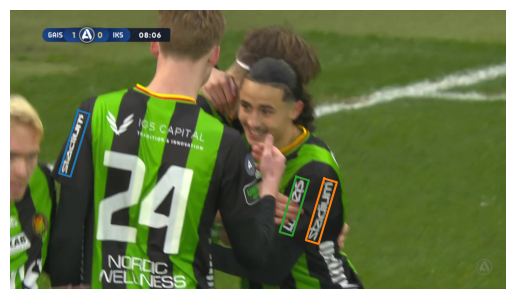

In [188]:
show_logo(random_image_file, random_label_file, 525)

<a id="section-3"></a>
### 3. 📊 Анализ распределения классов (брендов)

In [146]:
data_train = []

for file in TRAIN_LABELS.glob("*.txt"):
    labels = np.loadtxt(file, ndmin=2)
    data_train.extend(labels)

data_train = np.array(data_train)

print(data_train.shape)

(13218, 9)


In [147]:
data_val = []

for file in VAL_LABELS.glob("*.txt"):
    labels = np.loadtxt(file, ndmin=2)
    data_val.extend(labels)

data_val = np.array(data_val)

print(data_val.shape)

(526, 9)


In [148]:
data_test = []

for file in TEST_LABELS.glob("*.txt"):
    labels = np.loadtxt(file, ndmin=2)
    data_test.extend(labels)

data_test = np.array(data_test)

print(data_test.shape)

(374, 9)


In [149]:
data_all = np.vstack((data_val, data_test, data_train))

In [150]:
print(data_all.shape)

(14118, 9)


Согласно документации obb https://docs.ultralytics.com/ru/datasets/obb , каждая разметка obb имеет формат:

class_id x1 y1 x2 y2 x3 y3 x4 y4 - 9 координат

В очищенном датасете содержится 14 118 объектов (логотипов), размеченных на 883 изображениях.

In [ ]:
# определю, логотипы с каким class_id встречаются чаще всего
ids, counts = np.unique(data_all[:, 0], return_counts=True)

df = pd.DataFrame({
    "ID бренда": ids.astype(int),
    "Количество изображений данного бренда": counts})
df = df.reset_index(drop=True)
df

,ID бренда,Количество изображений данного бренда
0,0,4
1,1,11
2,2,2
3,3,7
4,4,8
...,...,...
626,672,19
627,673,33
628,674,39
629,675,9


In [185]:
df = df.sort_values("Количество изображений данного бренда", ascending=False)
df = df.reset_index(drop=True)
df

,ID бренда,Количество изображений данного бренда
0,600,1284
1,495,685
2,443,399
3,342,367
4,621,195
...,...,...
626,79,1
627,40,1
628,58,1
629,46,1


Бренды с class_id = 600, 495, 443, 342, 621 встречаются чаще всего. Определю что это за бренды с помощью следующей функцией:

In [217]:
def show_class_images(class_id, n=5):
    count = 0

    for label_file in TRAIN_LABELS.glob("*.txt"):
        data = np.loadtxt(label_file, ndmin=2)

        if class_id in data[:, 0]:
            image_file = TRAIN_IMAGES / (label_file.stem + ".jpg")
            show_logo(image_file, label_file, class_id)

            count += 1

            if count == n:
                break

Class ID на изображении ниже:600


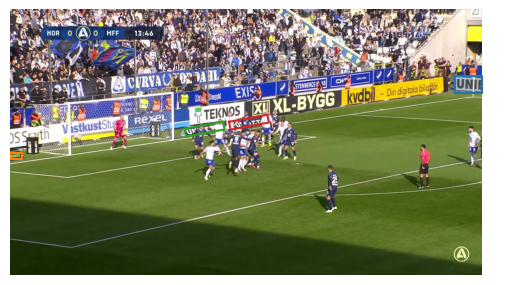

Class ID на изображении ниже:600


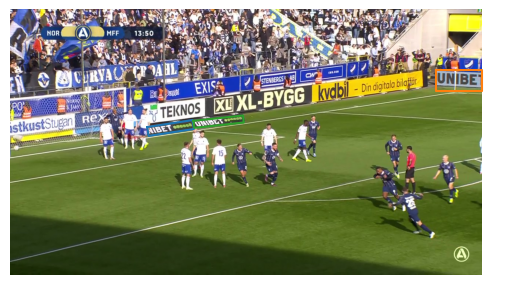

Class ID на изображении ниже:600


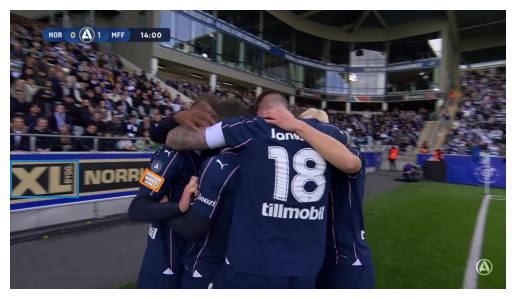

Class ID на изображении ниже:600


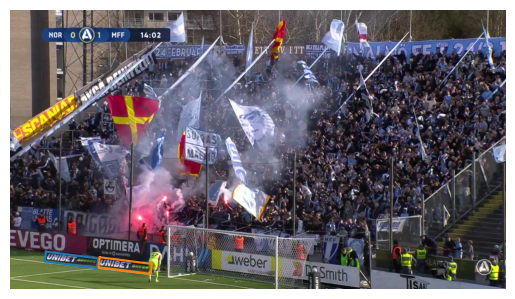

Class ID на изображении ниже:600


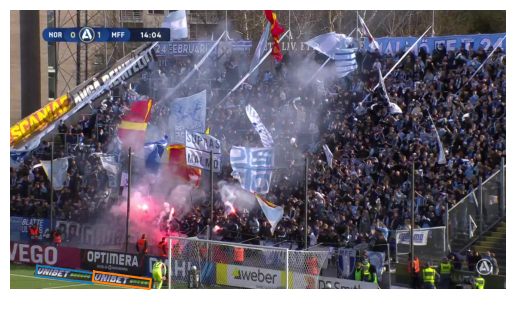

In [218]:
show_class_images(600, 5)

Class ID на изображении ниже:495


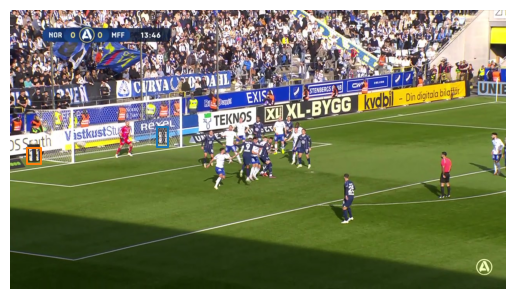

Class ID на изображении ниже:495


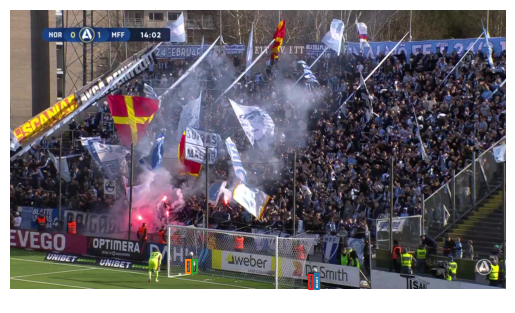

Class ID на изображении ниже:495


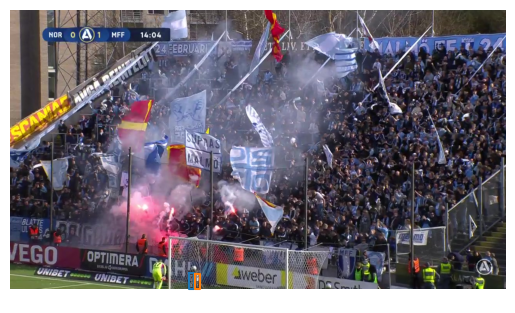

Class ID на изображении ниже:495


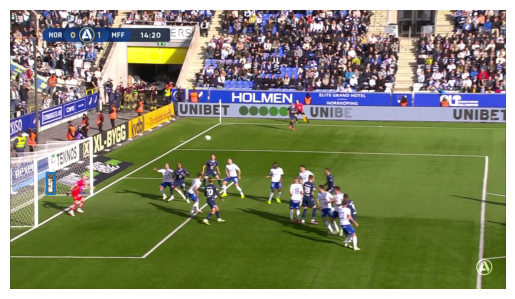

Class ID на изображении ниже:495


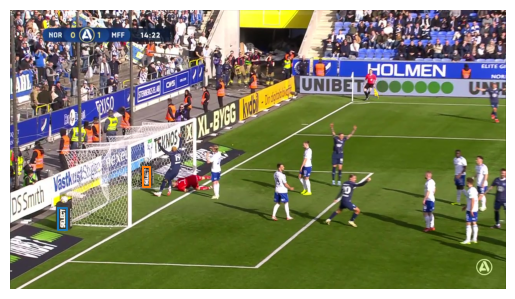

In [219]:
show_class_images(495, 5)

Class ID на изображении ниже:443


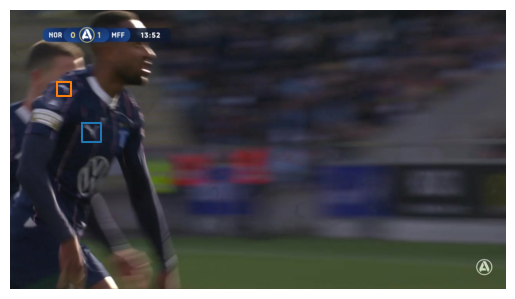

Class ID на изображении ниже:443


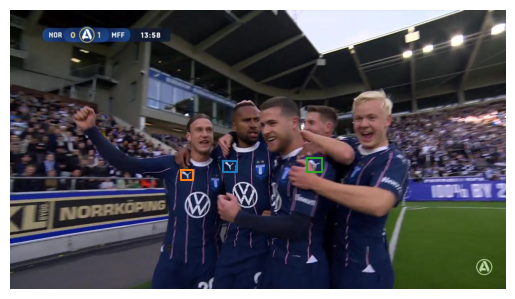

Class ID на изображении ниже:443


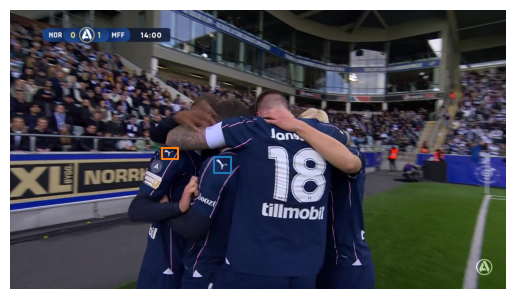

Class ID на изображении ниже:443


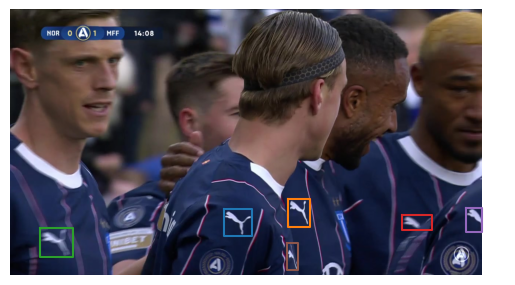

Class ID на изображении ниже:443


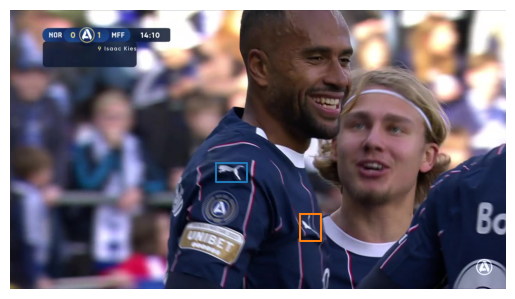

In [220]:
show_class_images(443, 5)

Class ID на изображении ниже:342


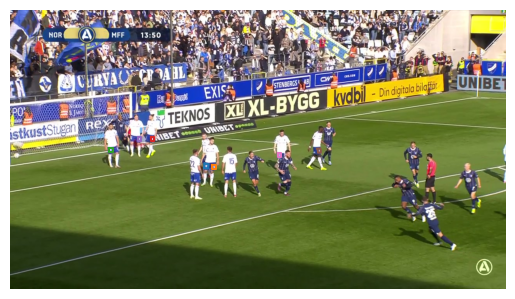

Class ID на изображении ниже:342


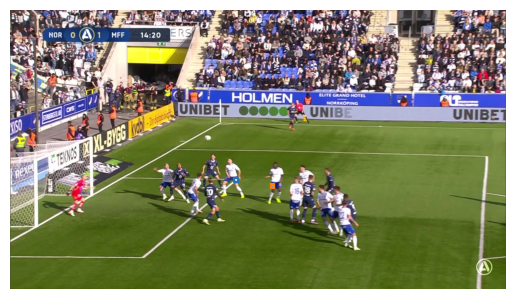

Class ID на изображении ниже:342


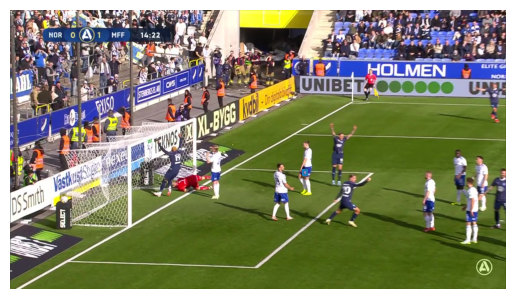

Class ID на изображении ниже:342


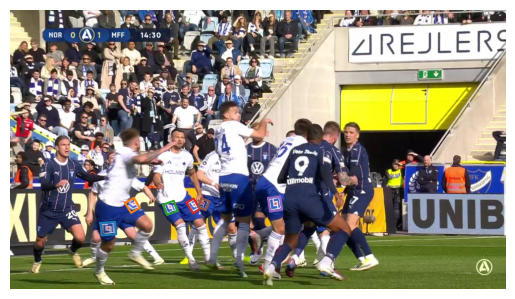

Class ID на изображении ниже:342


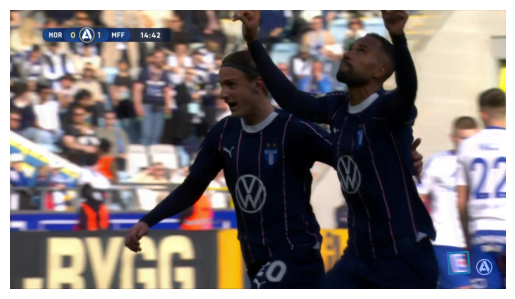

Class ID на изображении ниже:342


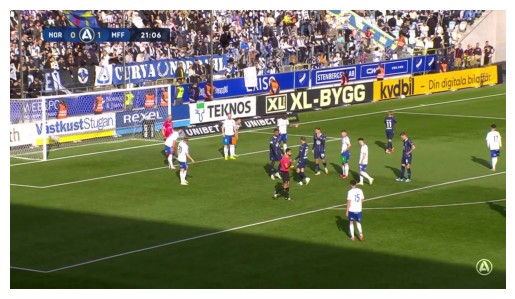

Class ID на изображении ниже:342


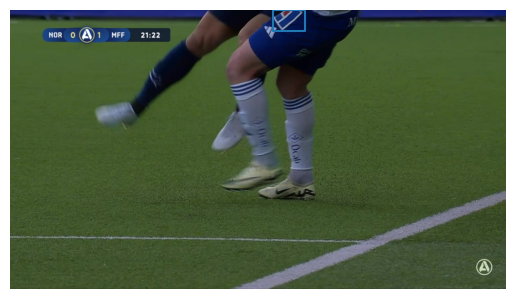

Class ID на изображении ниже:342


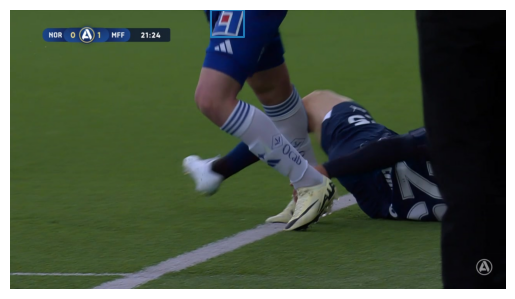

Class ID на изображении ниже:342


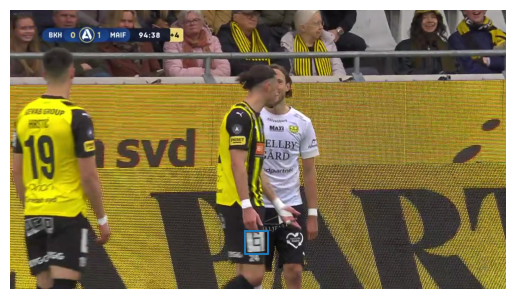

Class ID на изображении ниже:342


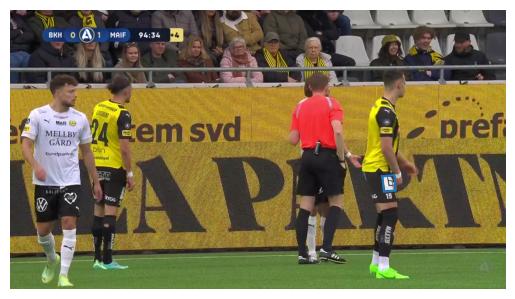

Class ID на изображении ниже:342


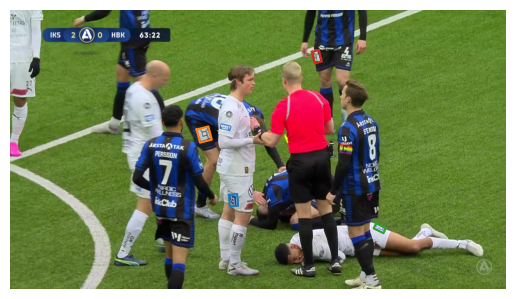

Class ID на изображении ниже:342


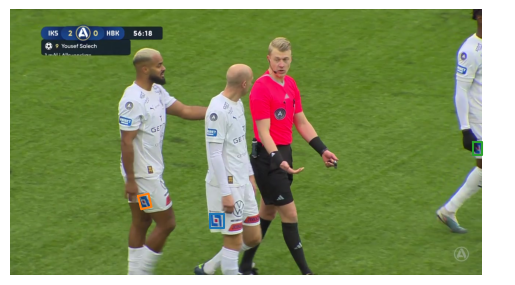

Class ID на изображении ниже:342


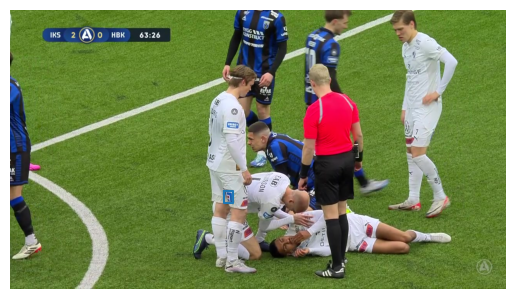

Class ID на изображении ниже:342


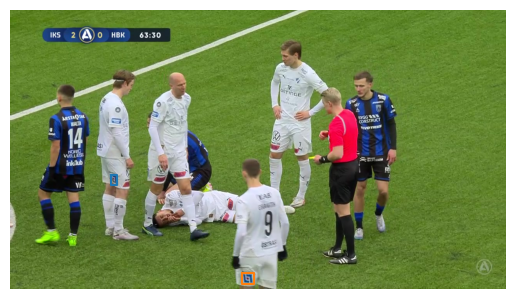

Class ID на изображении ниже:342


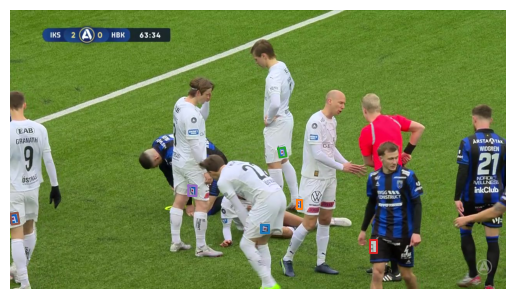

In [221]:
show_class_images(342, 15)

Class ID на изображении ниже:621


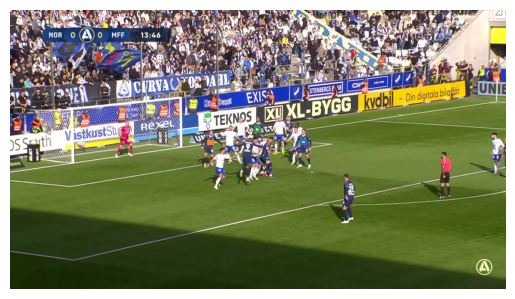

Class ID на изображении ниже:621


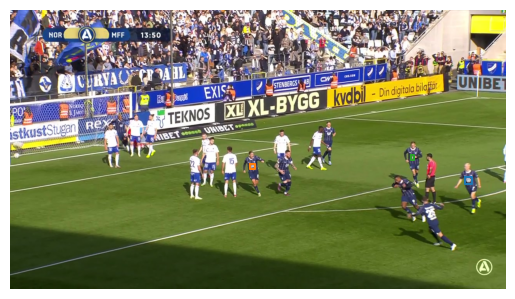

Class ID на изображении ниже:621


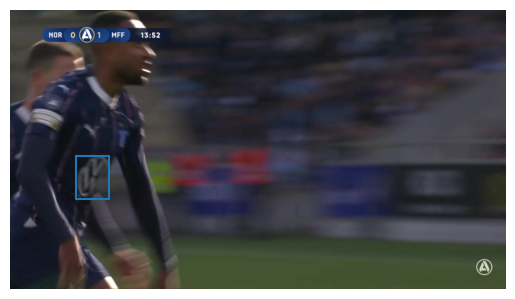

Class ID на изображении ниже:621


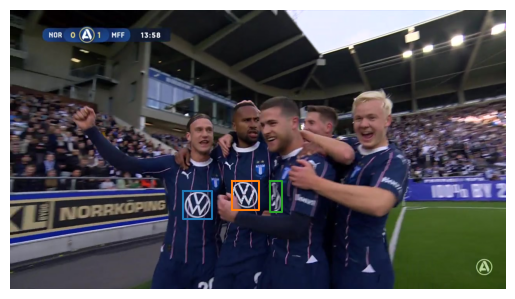

Class ID на изображении ниже:621


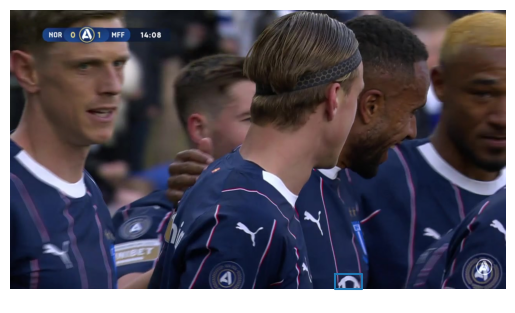

In [222]:
show_class_images(621, 5)

По результатам визуального анализа удалось выделить пять наиболее часто встречающихся брендов: Unibet, Select, Puma, Länsförsäkringar и Volkswagen. На некоторых изображениях заметно снижение качества и размытие, также есть вероятность, что при первоначальной разметке были отмечены не все логотипы. Эти особенности стоит учитывать в дальнейшей работе с датасетом. Тем не менее уже на текущем этапе результаты выглядят достаточно перспективно.

<a id="section-4"></a>
### 4. 📐 Анализ геометрических характеристик логотипов

<a id="section-5"></a>
### 5. ✅ Проверка качества и корректности разметки

<a id="section-6"></a>
### 6. 🔎 Анализ сложных случаев обнаружения логотипов

<a id="section-7"></a>
### 7. ⚖️ Сравнение обучающей, валидационной и тестовой выборок

<a id="section-8"></a>
### 8. 🧪 Исследование методов аугментации данных

<a id="section-9"></a>
### 9. 📝 Выводы и подготовка данных к обучению модели